In [67]:
import pandas as pd
import numpy as np
import boto3
from sklearn.model_selection import train_test_split
import sagemaker 
from sagemaker import Session 
import io
import seaborn as sns
import matplotlib.pyplot as plt
import sagemaker.amazon.common as smac
import os
from sagemaker import image_uris
from sklearn.preprocessing import OneHotEncoder,LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, precision_score,confusion_matrix, recall_score

In [68]:
df=pd.read_csv("loan_approval_data.csv")
df.isnull().sum()

Applicant_ID          50
Applicant_Income      50
Coapplicant_Income    50
Employment_Status     50
Age                   50
Marital_Status        50
Dependents            50
Credit_Score          50
Existing_Loans        50
DTI_Ratio             50
Savings               50
Collateral_Value      50
Loan_Amount           50
Loan_Term             50
Loan_Purpose          50
Property_Area         50
Education_Level       50
Gender                50
Employer_Category     50
Loan_Approved         50
dtype: int64

In [69]:
#Filling missing values
categorical_col=df.select_dtypes(include=["object"]).columns
numerical_col=df.select_dtypes(include=["number"]).columns

In [70]:
from sklearn.impute import SimpleImputer
cat_col=SimpleImputer(strategy="most_frequent")
df[categorical_col]=cat_col.fit_transform(df[categorical_col])

num_col=SimpleImputer(strategy='mean')
df[numerical_col]=num_col.fit_transform(df[numerical_col])

In [71]:
df.isnull().sum()

Applicant_ID          0
Applicant_Income      0
Coapplicant_Income    0
Employment_Status     0
Age                   0
Marital_Status        0
Dependents            0
Credit_Score          0
Existing_Loans        0
DTI_Ratio             0
Savings               0
Collateral_Value      0
Loan_Amount           0
Loan_Term             0
Loan_Purpose          0
Property_Area         0
Education_Level       0
Gender                0
Employer_Category     0
Loan_Approved         0
dtype: int64

In [72]:
df.sample(2)

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
84,85.0,5561.0,60.0,Salaried,42.0,Married,3.0,601.0,3.0,0.29,15471.0,48700.0,33692.0,36.0,Business,Semiurban,Not Graduate,Male,Private,No
787,788.0,13157.0,1249.0,Contract,36.0,Married,3.0,748.0,3.0,0.57,5957.0,29250.0,38177.0,60.0,Business,Rural,Not Graduate,Male,Government,No


Text(0.5, 1.0, 'Is Loan approved')

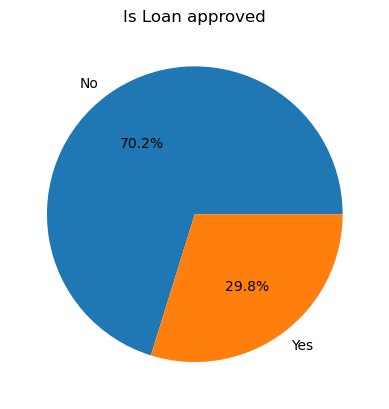

In [73]:
#EDA
import matplotlib.pyplot as plt
classes_count=df["Loan_Approved"].value_counts()
plt.pie(classes_count,labels=["No","Yes"],autopct="%1.1f%%")
plt.title("Is Loan approved")

[Text(0, 0, '643'), Text(0, 0, '357')]

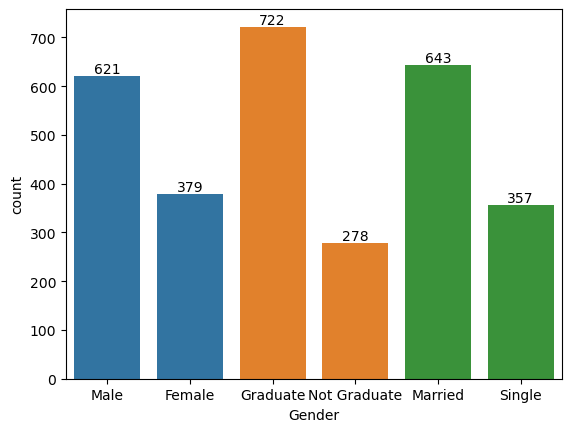

In [74]:
#analyze categories
gender_cnt=df["Gender"].value_counts()
ax=sns.barplot(gender_cnt)
ax.bar_label(ax.containers[0])

edu_cnt=df["Education_Level"].value_counts()
ax=sns.barplot(edu_cnt)
ax.bar_label(ax.containers[1])

mat_cnt=df["Marital_Status"].value_counts()
ax=sns.barplot(mat_cnt)
ax.bar_label(ax.containers[2])

<Axes: xlabel='Applicant_Income', ylabel='Count'>

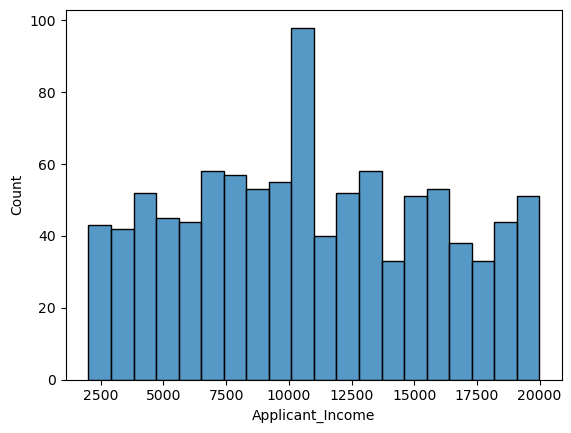

In [75]:
#analyze income 
sns.histplot(
    data=df,
    x="Applicant_Income",
    bins=20
)


<Axes: xlabel='Coapplicant_Income', ylabel='Count'>

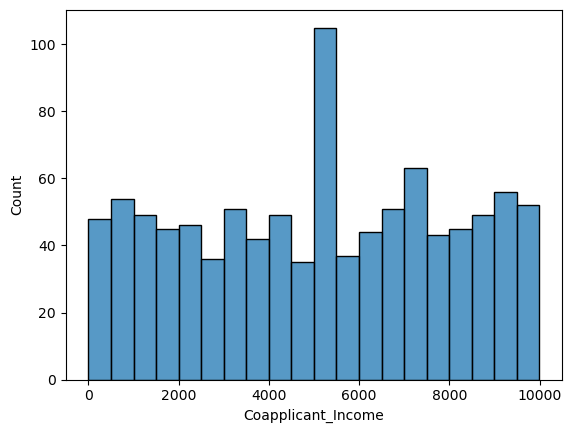

In [76]:
sns.histplot(
    data=df,
    x="Coapplicant_Income",
    bins=20
)

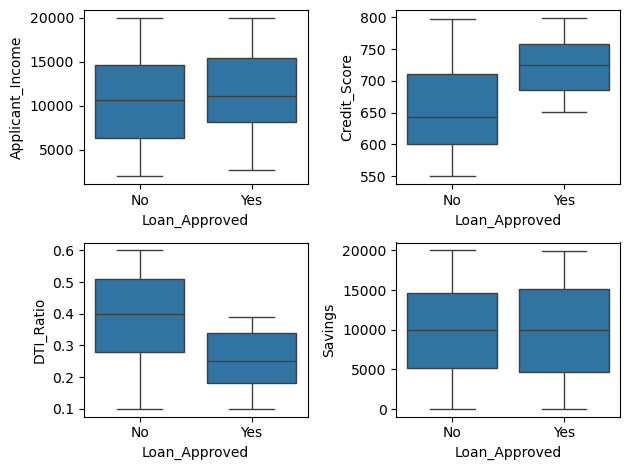

In [77]:
#outliers -box plots
fig,axes=plt.subplots(2,2)
sns.boxplot(ax=axes[0,0],data=df,x="Loan_Approved",y="Applicant_Income")
sns.boxplot(ax=axes[0,1],data=df,x="Loan_Approved",y="Credit_Score")
sns.boxplot(ax=axes[1,0],data=df,x="Loan_Approved",y="DTI_Ratio")
sns.boxplot(ax=axes[1,1],data=df,x="Loan_Approved",y="Savings")
plt.tight_layout()

<Axes: xlabel='Credit_Score', ylabel='Count'>

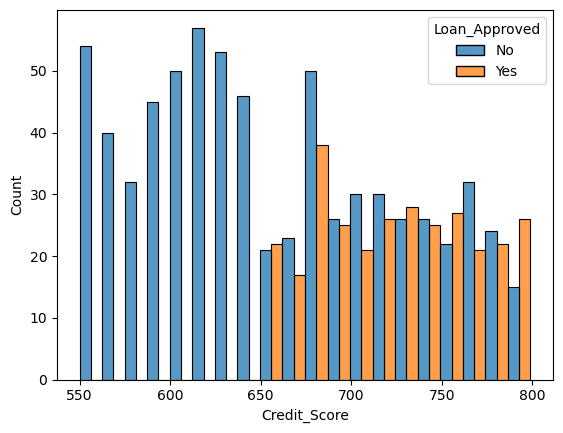

In [78]:
sns.histplot(
    data=df,
    x="Credit_Score",
    hue="Loan_Approved",
    bins=20,
    multiple="dodge",
)

<Axes: xlabel='Applicant_Income', ylabel='Count'>

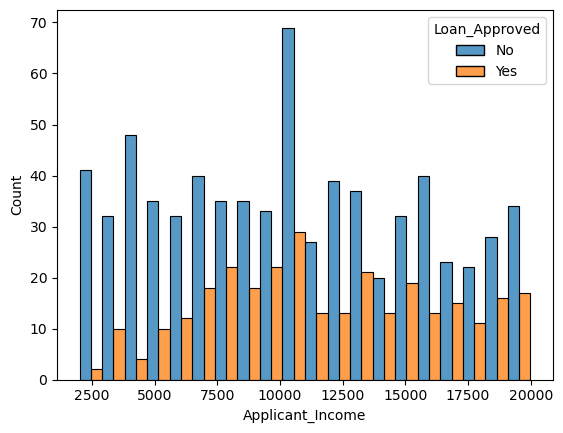

In [79]:
sns.histplot(
    data=df,
    x="Applicant_Income",
    hue="Loan_Approved",
    bins=20,
    multiple="dodge",
)

<Axes: xlabel='DTI_Ratio', ylabel='Count'>

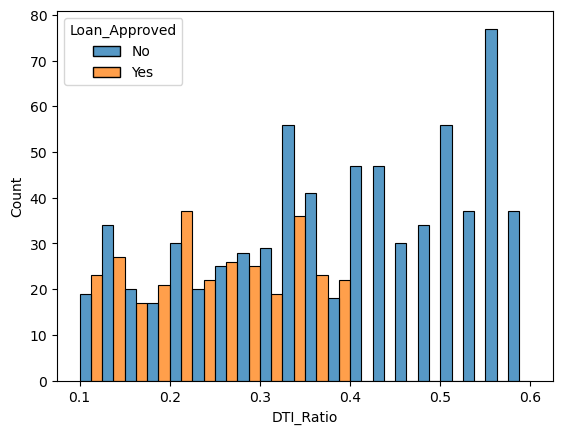

In [80]:
sns.histplot(
    data=df,
    x="DTI_Ratio",
    hue="Loan_Approved",
    bins=20,
    multiple="dodge",
)

In [81]:
df=df.drop("Applicant_ID",axis=1)

In [82]:
df.isnull().sum()

Applicant_Income      0
Coapplicant_Income    0
Employment_Status     0
Age                   0
Marital_Status        0
Dependents            0
Credit_Score          0
Existing_Loans        0
DTI_Ratio             0
Savings               0
Collateral_Value      0
Loan_Amount           0
Loan_Term             0
Loan_Purpose          0
Property_Area         0
Education_Level       0
Gender                0
Employer_Category     0
Loan_Approved         0
dtype: int64

In [83]:
#encoding
# Convert manually (BEST METHOD)
df["Education_Level"] = df["Education_Level"].map({
    "Graduate": 1,
    "Not Graduate": 0
})

In [84]:
df["Loan_Approved"] = df["Loan_Approved"].map({
    "Yes": 1,
    "No": 0
})

In [85]:
df.sample(2)

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
430,16191.0,2043.0,Unemployed,37.0,Married,3.0,719.0,1.0,0.16,10715.0,6200.0,14526.0,36.0,Business,Rural,0,Male,Government,1
276,6014.0,2745.0,Salaried,32.0,Married,3.0,692.0,4.0,0.37,17424.0,4923.0,24177.0,48.0,Business,Urban,1,Male,Private,1


In [86]:
cols = ["Employment_Status","Marital_Status","Loan_Purpose",
        "Property_Area","Gender","Employer_Category"] 

ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown='ignore')

encoded = ohe.fit_transform(df[cols])

encoded_df = pd.DataFrame(
    encoded,
    columns=ohe.get_feature_names_out(cols),
    index=df.index
)

df = pd.concat([df.drop(columns=cols), encoded_df], axis=1)
df.sample(2)

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Education_Level,Loan_Approved,Employment_Status_Salaried,Employment_Status_Self-employed,Employment_Status_Unemployed,Marital_Status_Single,Loan_Purpose_Car,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
257,3060.0,9175.0,34.0,2.0,675.0,3.0,0.17,7829.0,17732.0,4691.0,36.0,0,1,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
676,7870.0,1000.0,51.0,2.0,751.0,1.0,0.25,2886.0,21988.0,16660.0,12.0,0,1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [87]:
#correlation heatmap
num_cols=df.select_dtypes("number")
corr_matrix=num_cols.corr()

<Axes: >

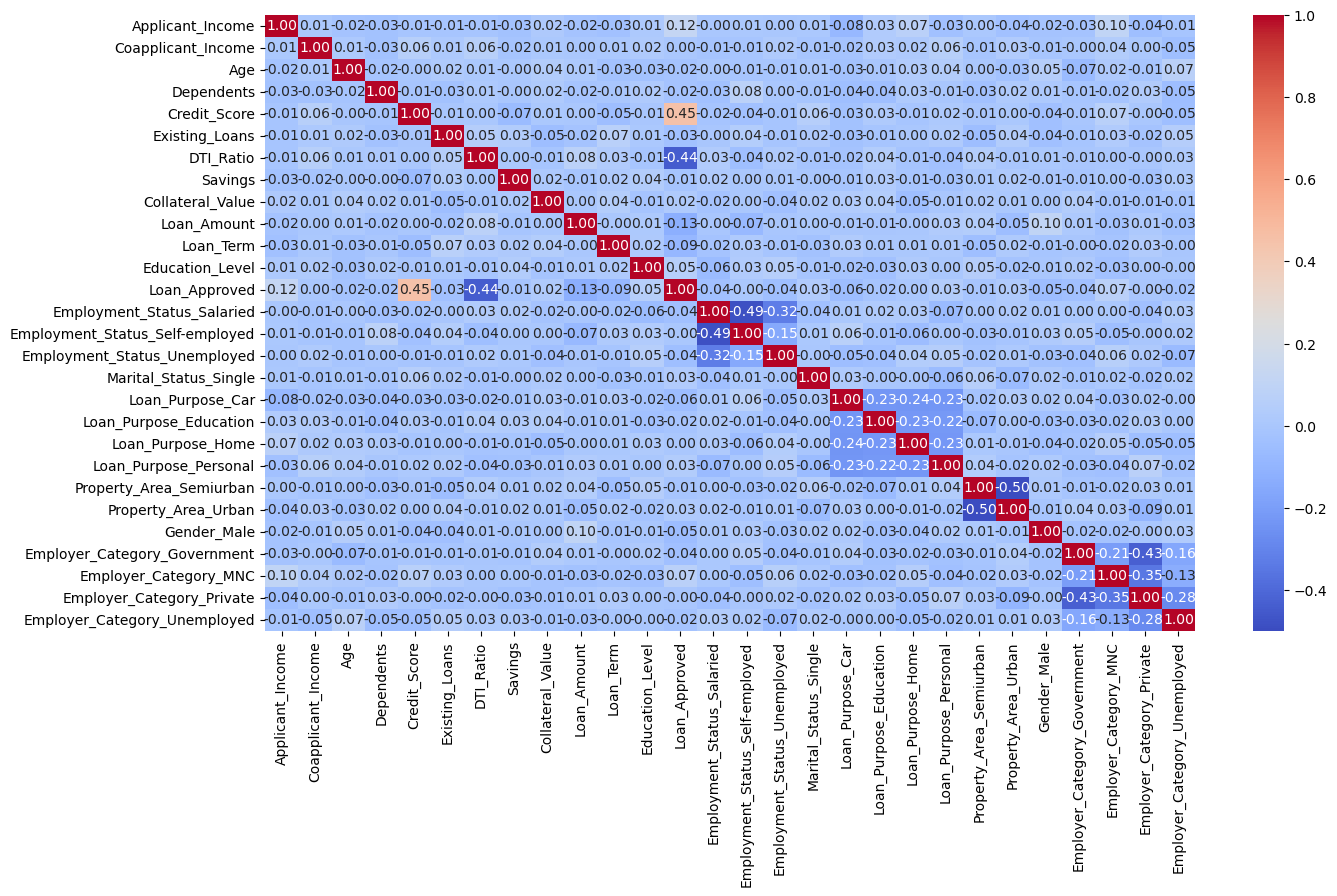

In [88]:
plt.figure(figsize =(15,8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

Feature Engineering

In [89]:
X=df.drop(columns=["Loan_Approved"])
y=df["Loan_Approved"]

#train test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,random_state=42)

#scaling

scaler=StandardScaler()
X_train_scaler=scaler.fit_transform(X_train)
X_test_scaler=scaler.transform(X_test)

Logistic Regression Results
Accuracy: 0.865
Precision: 0.8644166666666666
Recall: 0.865

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.91      0.90       139
           1       0.78      0.77      0.78        61

    accuracy                           0.86       200
   macro avg       0.84      0.84      0.84       200
weighted avg       0.86      0.86      0.86       200



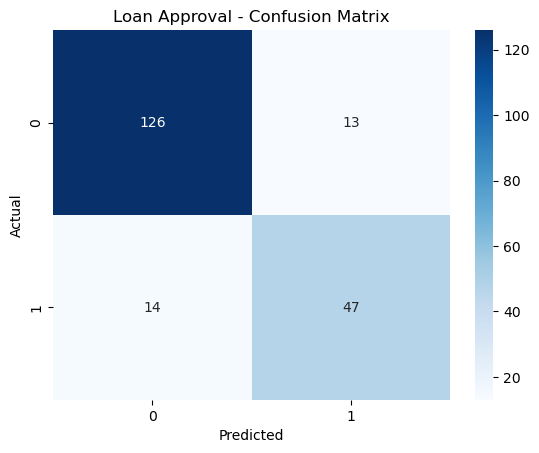

In [90]:
#using logisticRegression 
from sklearn.linear_model import LogisticRegression
model=LogisticRegression(max_iter=1000)
model.fit(X_train_scaler,y_train)
y_pred=model.predict(X_test_scaler)
#evalution
print("Logistic Regression Results")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(
    y_test, y_pred, average="weighted", zero_division=0
))
print("Recall:", recall_score(
    y_test, y_pred, average="weighted", zero_division=0
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.title("Loan Approval - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [91]:
#Lets create sagemaker session
sagemaker_session=sagemaker.Session()
#define the bucket name
bucket_name="bappy-bucket-2026"
#define the prefix
prefix="logistic-learner"
#get the execution role
role=sagemaker.get_execution_role()

print("Bucket:", bucket_name)
print("Prefix:", prefix)
print("Role:", role)
print("Region:", sagemaker_session.boto_region_name)

Bucket: bappy-bucket-2026
Prefix: logistic-learner
Role: arn:aws:iam::460241088603:role/service-role/AmazonSageMaker-ExecutionRole-20261030T200362
Region: ap-south-1


In [92]:
s3 = boto3.client("s3")

try:
    s3.head_bucket(Bucket=bucket_name)
    print("S3 bucket exists and is accessible!")
except Exception as e:
    print("Bucket access error:", e)


S3 bucket exists and is accessible!


In [93]:
# Create the buffer
buf = io.BytesIO()

# Convert training data to NumPy arrays
X_train_np = np.asarray(X_train, dtype=np.float32)
y_train_np = np.asarray(y_train, dtype=np.float32).reshape(-1)

# Write data in SageMaker RecordIO-Protobuf format
smac.write_numpy_to_dense_tensor(
    buf,
    X_train_np,
    y_train_np
)

# Reset buffer position
buf.seek(0)
print("Buffer closed:", buf.closed)
print("Buffer size:", buf.getbuffer().nbytes, "bytes")
print("Training data converted successfully!")
print("X_train shape:", X_train_np.shape)
print("y_train shape:", y_train_np.shape)
print("Buffer size:", buf.getbuffer().nbytes, "bytes")

Buffer closed: False
Buffer size: 121600 bytes
Training data converted successfully!
X_train shape: (800, 27)
y_train shape: (800,)
Buffer size: 121600 bytes


In [94]:
key = "loan-approval"
s3_key = os.path.join(prefix, "train", key)

s3 = boto3.resource("s3")

s3.Bucket(bucket_name).Object(s3_key).upload_fileobj(buf)

s3_train_data = f"s3://{bucket_name}/{s3_key}"

print("Data uploaded successfully:", s3_train_data)

Data uploaded successfully: s3://bappy-bucket-2026/logistic-learner/train/loan-approval


In [101]:
# Convert X_test and y_test into NumPy arrays
X_test_np = np.asarray(X_test, dtype=np.float32)
y_test_np = np.asarray(y_test, dtype=np.float32).reshape(-1)

# Create the buffer
buf = io.BytesIO()

# Convert data into RecordIO-Protobuf format
smac.write_numpy_to_dense_tensor(buf, X_test_np, y_test_np)

# Reset buffer position
buf.seek(0)

print("Test data converted successfully")
print("Buffer size:", buf.getbuffer().nbytes, "bytes")

Test data converted successfully
Buffer size: 30400 bytes


In [102]:
# Define the file name
key = "loan-approval-test"

# Define S3 object path
s3_key = os.path.join(prefix, "test", key)

# Upload data to S3
boto3.resource("s3").Bucket(bucket_name).Object(s3_key).upload_fileobj(buf)

# Define the S3 path
s3_test_data = f"s3://{bucket_name}/{s3_key}"

print("Test data uploaded successfully:", s3_test_data)

Test data uploaded successfully: s3://bappy-bucket-2026/logistic-learner/test/loan-approval-test


In [103]:
#output location 
output_location=f"s3://{bucket_name}/{prefix}/output"
output_location

's3://bappy-bucket-2026/logistic-learner/output'

In [104]:
container = sagemaker.image_uris.retrieve(
    framework="linear-learner",
    region=boto3.Session().region_name,
    image_scope="training"
)

print("Training container:", container)

INFO:sagemaker.image_uris:Defaulting to the only supported framework/algorithm version: 1.
INFO:sagemaker.image_uris:Ignoring unnecessary instance type: None.


Training container: 991648021394.dkr.ecr.ap-south-1.amazonaws.com/linear-learner:1


In [105]:
#define the estimator
linear=sagemaker.estimator.Estimator(container,role,instance_count=1,instance_type="ml.m4.xlarge",output_path=output_location,sagemaker_session=sagemaker.Session())

In [106]:
# Configure for loan approval binary classification
linear.set_hyperparameters(
    feature_dim=X_train_np.shape[1],
    predictor_type="binary_classifier",
    mini_batch_size=100,
    epochs=6,
    num_models=32,
    loss="logistic"
)

print("Linear Learner estimator configured successfully!")
print("Number of features:", X_train_np.shape[1])

Linear Learner estimator configured successfully!
Number of features: 27


In [107]:
linear.fit({"train": s3_train_data})

INFO:sagemaker:Creating training-job with name: linear-learner-2026-11-04-15-39-53-152


2026-11-04 15:39:53 Starting - Starting the training job...
2026-11-04 15:40:07 Starting - Preparing the instances for training...
2026-11-04 15:40:37 Downloading - Downloading input data...
2026-11-04 15:41:04 Downloading - Downloading the training image.........
2026-11-04 15:42:45 Training - Training image download completed. Training in progress...Docker entrypoint called with argument(s): train
Running default environment configuration script
[11/04/2026 15:43:11 INFO 140572174096192] Reading default configuration from /opt/amazon/lib/python3.8/site-packages/algorithm/resources/default-input.json: {'mini_batch_size': '1000', 'epochs': '15', 'feature_dim': 'auto', 'use_bias': 'true', 'binary_classifier_model_selection_criteria': 'accuracy', 'f_beta': '1.0', 'target_recall': '0.8', 'target_precision': '0.8', 'num_models': 'auto', 'num_calibration_samples': '10000000', 'init_method': 'uniform', 'init_scale': '0.07', 'init_sigma': '0.01', 'init_bias': '0.0', 'optimizer': 'auto', 'loss

In [108]:
# Deploy the trained Linear Learner model
predictor = linear.deploy(
    initial_instance_count=1,
    instance_type="ml.m4.xlarge"
)

print("Model deployed successfully!")
print("Endpoint name:", predictor.endpoint_name)

INFO:sagemaker:Creating model with name: linear-learner-2026-11-04-15-50-43-732
INFO:sagemaker:Creating endpoint-config with name linear-learner-2026-11-04-15-50-43-732
INFO:sagemaker:Creating endpoint with name linear-learner-2026-11-04-15-50-43-732


--------!Model deployed successfully!
Endpoint name: linear-learner-2026-11-04-15-50-43-732


In [110]:
# Configure input and output formats
predictor.serializer = sagemaker.serializers.CSVSerializer()
predictor.deserializer = sagemaker.deserializers.JSONDeserializer()

print("Serializer and deserializer configured successfully!")

Serializer and deserializer configured successfully!


In [111]:
#prediction
results=predictor.predict(X_test)

In [112]:
results

{'predictions': [{'score': 0.006351693067699671, 'predicted_label': 0},
  {'score': 0.003860344411805272, 'predicted_label': 0},
  {'score': 0.0007096974295563996, 'predicted_label': 0},
  {'score': 0.5355520248413086, 'predicted_label': 1},
  {'score': 0.001260049408301711, 'predicted_label': 0},
  {'score': 0.9698293805122375, 'predicted_label': 1},
  {'score': 0.01590448059141636, 'predicted_label': 0},
  {'score': 0.2647467255592346, 'predicted_label': 0},
  {'score': 0.008625409565865993, 'predicted_label': 0},
  {'score': 0.29571670293807983, 'predicted_label': 0},
  {'score': 0.022768108174204826, 'predicted_label': 0},
  {'score': 0.0095219099894166, 'predicted_label': 0},
  {'score': 0.8188946843147278, 'predicted_label': 1},
  {'score': 0.017599640414118767, 'predicted_label': 0},
  {'score': 0.9477840065956116, 'predicted_label': 1},
  {'score': 0.22343678772449493, 'predicted_label': 0},
  {'score': 0.12976349890232086, 'predicted_label': 0},
  {'score': 0.00146010704338550

In [113]:
print("predictor:", "predictor" in globals())

predictor: True


In [114]:
predictor.delete_endpoint()
print("SageMaker endpoint deleted successfully!")

INFO:sagemaker:Deleting endpoint configuration with name: linear-learner-2026-11-04-15-50-43-732
INFO:sagemaker:Deleting endpoint with name: linear-learner-2026-11-04-15-50-43-732


SageMaker endpoint deleted successfully!


In [116]:
print("MODEL STATUS")
print("=" * 50)

print("Model:", type(model).__name__)
print("Scaler:", type(scaler).__name__)

print("\nModel input features:", model.n_features_in_)
print("Scaler input features:", scaler.n_features_in_)

print("\nTraining features:", X_train.shape[1])
print("Testing features:", X_test.shape[1])

print("\nModel classes:", model.classes_)

print("\nModel and scaler feature counts match:",
      model.n_features_in_ == scaler.n_features_in_ == X_train.shape[1])

print("\nFeature names:")
print(X_train.columns.tolist())

MODEL STATUS
Model: LogisticRegression
Scaler: StandardScaler

Model input features: 27
Scaler input features: 27

Training features: 27
Testing features: 27

Model classes: [0 1]

Model and scaler feature counts match: True

Feature names:
['Applicant_Income', 'Coapplicant_Income', 'Age', 'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings', 'Collateral_Value', 'Loan_Amount', 'Loan_Term', 'Education_Level', 'Employment_Status_Salaried', 'Employment_Status_Self-employed', 'Employment_Status_Unemployed', 'Marital_Status_Single', 'Loan_Purpose_Car', 'Loan_Purpose_Education', 'Loan_Purpose_Home', 'Loan_Purpose_Personal', 'Property_Area_Semiurban', 'Property_Area_Urban', 'Gender_Male', 'Employer_Category_Government', 'Employer_Category_MNC', 'Employer_Category_Private', 'Employer_Category_Unemployed']


In [117]:

import joblib
import os

# Create project directory
os.makedirs("loan_approval_project", exist_ok=True)

# Save model, scaler and feature information together
model_artifact = {
    "model": model,
    "scaler": scaler,
    "feature_names": X_train.columns.tolist(),
    "target_classes": model.classes_.tolist()
}

model_path = "loan_approval_project/loan_approval_model.pkl"

joblib.dump(model_artifact, model_path)

print("=" * 50)
print("MODEL SAVED SUCCESSFULLY")
print("=" * 50)

print("Model path:", model_path)
print("Model type:", type(model).__name__)
print("Scaler type:", type(scaler).__name__)
print("Total features:", len(model_artifact["feature_names"]))
print("File size:", round(os.path.getsize(model_path) / 1024, 2), "KB")


MODEL SAVED SUCCESSFULLY
Model path: loan_approval_project/loan_approval_model.pkl
Model type: LogisticRegression
Scaler type: StandardScaler
Total features: 27
File size: 3.58 KB


In [118]:

# CELL 3: INSPECT ORIGINAL CATEGORICAL VALUES

categorical_columns = [
    "Education_Level",
    "Employment_Status",
    "Marital_Status",
    "Loan_Purpose",
    "Property_Area",
    "Gender",
    "Employer_Category"
]

print("=" * 60)
print("ORIGINAL DATASET - CATEGORICAL VALUE INSPECTION")
print("=" * 60)

for col in categorical_columns:
    print(f"\n{col}:")
    if col in df.columns:
        print(sorted(df[col].dropna().astype(str).unique().tolist()))
    else:
        print("Column not found in df.")

print("\nTarget values:")
print(df["Loan_Approved"].dropna().unique().tolist())

print("\nInspection completed.")


ORIGINAL DATASET - CATEGORICAL VALUE INSPECTION

Education_Level:
['0', '1']

Employment_Status:
Column not found in df.

Marital_Status:
Column not found in df.

Loan_Purpose:
Column not found in df.

Property_Area:
Column not found in df.

Gender:
Column not found in df.

Employer_Category:
Column not found in df.

Target values:
[0, 1]

Inspection completed.


In [119]:

# CELL 4: INSPECT TRAINING PREPROCESSING

print("=" * 60)
print("TRAINING DATA PREPROCESSING INSPECTION")
print("=" * 60)

print("\n1. Original/current dataframe columns:")
print(df.columns.tolist())

print("\n2. Training feature columns:")
print(X_train.columns.tolist())

print("\n3. Training feature sample:")
display(X_train.head())

print("\n4. Data types of training features:")
display(X_train.dtypes)

print("\n5. Scaler parameters:")
print("Mean shape:", scaler.mean_.shape)
print("Scale shape:", scaler.scale_.shape)

print("\n6. Target distribution:")
print(pd.Series(y_train).value_counts())

print("\n7. Check original raw CSV separately:")
raw_df = pd.read_csv("loan_approval_data.csv")

print("Raw dataset shape:", raw_df.shape)
print("Raw dataset columns:")
print(raw_df.columns.tolist())

print("\nOriginal categorical values:")
for col in raw_df.select_dtypes(include=["object", "category"]).columns:
    print(col, ":", raw_df[col].dropna().unique().tolist())


TRAINING DATA PREPROCESSING INSPECTION

1. Original/current dataframe columns:
['Applicant_Income', 'Coapplicant_Income', 'Age', 'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings', 'Collateral_Value', 'Loan_Amount', 'Loan_Term', 'Education_Level', 'Loan_Approved', 'Employment_Status_Salaried', 'Employment_Status_Self-employed', 'Employment_Status_Unemployed', 'Marital_Status_Single', 'Loan_Purpose_Car', 'Loan_Purpose_Education', 'Loan_Purpose_Home', 'Loan_Purpose_Personal', 'Property_Area_Semiurban', 'Property_Area_Urban', 'Gender_Male', 'Employer_Category_Government', 'Employer_Category_MNC', 'Employer_Category_Private', 'Employer_Category_Unemployed']

2. Training feature columns:
['Applicant_Income', 'Coapplicant_Income', 'Age', 'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings', 'Collateral_Value', 'Loan_Amount', 'Loan_Term', 'Education_Level', 'Employment_Status_Salaried', 'Employment_Status_Self-employed', 'Employment_Status_Unemployed', 'M

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Education_Level,Employment_Status_Salaried,Employment_Status_Self-employed,Employment_Status_Unemployed,Marital_Status_Single,Loan_Purpose_Car,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
29,5890.000000,8041.0,31.000000,0.0,603.000000,0.000000,0.11,11906.0,8150.000000,29287.000000,12.0,0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
535,4779.000000,529.0,50.000000,0.0,614.000000,0.000000,0.21,5369.0,5430.000000,14786.000000,72.0,0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
695,10852.571579,8927.0,36.000000,0.0,584.000000,4.000000,0.22,3186.0,24802.792632,20522.825263,48.0,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
557,2384.000000,2113.0,39.971579,1.0,726.000000,4.000000,0.34,11882.0,48542.000000,13312.000000,24.0,1,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
836,5228.000000,5249.0,42.000000,1.0,676.033684,1.950526,0.18,17669.0,24802.792632,13906.000000,84.0,1,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0



4. Data types of training features:


Applicant_Income                   float64
Coapplicant_Income                 float64
Age                                float64
Dependents                         float64
Credit_Score                       float64
Existing_Loans                     float64
DTI_Ratio                          float64
Savings                            float64
Collateral_Value                   float64
Loan_Amount                        float64
Loan_Term                          float64
Education_Level                      int64
Employment_Status_Salaried         float64
Employment_Status_Self-employed    float64
Employment_Status_Unemployed       float64
Marital_Status_Single              float64
Loan_Purpose_Car                   float64
Loan_Purpose_Education             float64
Loan_Purpose_Home                  float64
Loan_Purpose_Personal              float64
Property_Area_Semiurban            float64
Property_Area_Urban                float64
Gender_Male                        float64
Employer_Ca


5. Scaler parameters:
Mean shape: (27,)
Scale shape: (27,)

6. Target distribution:
Loan_Approved
0    563
1    237
Name: count, dtype: int64

7. Check original raw CSV separately:
Raw dataset shape: (1000, 20)
Raw dataset columns:
['Applicant_ID', 'Applicant_Income', 'Coapplicant_Income', 'Employment_Status', 'Age', 'Marital_Status', 'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings', 'Collateral_Value', 'Loan_Amount', 'Loan_Term', 'Loan_Purpose', 'Property_Area', 'Education_Level', 'Gender', 'Employer_Category', 'Loan_Approved']

Original categorical values:
Employment_Status : ['Salaried', 'Self-employed', 'Contract', 'Unemployed']
Marital_Status : ['Married', 'Single']
Loan_Purpose : ['Personal', 'Car', 'Business', 'Home', 'Education']
Property_Area : ['Urban', 'Semiurban', 'Rural']
Education_Level : ['Not Graduate', 'Graduate']
Gender : ['Female', 'Male']
Employer_Category : ['Private', 'Government', 'Unemployed', 'MNC', 'Business']
Loan_Approved : ['No', 'Yes

In [120]:
 # CELL 5: VERIFY ENCODING AND TARGET MAPPING

print("EDUCATION LEVEL ENCODING")
print(raw_df.groupby("Education_Level")["Loan_Approved"].count())

print("\nTARGET ENCODING")
print(raw_df.groupby("Loan_Approved").size())

print("\nTRAINING TARGET CLASSES")
print("Model classes:", model.classes_.tolist())

print("\nFEATURE ORDER CHECK")
print("Number of features:", len(model.feature_names_in_))
print("Feature order matches X_train:",
      list(model.feature_names_in_) == X_train.columns.tolist())

print("\nSAVED MODEL CHECK")
print("Saved model exists:", os.path.exists(model_path))

EDUCATION LEVEL ENCODING
Education_Level
Graduate        638
Not Graduate    265
Name: Loan_Approved, dtype: int64

TARGET ENCODING
Loan_Approved
No     652
Yes    298
dtype: int64

TRAINING TARGET CLASSES
Model classes: [0, 1]

FEATURE ORDER CHECK


AttributeError: 'LogisticRegression' object has no attribute 'feature_names_in_'

In [121]:
# CELL 5: VERIFY ENCODING AND TARGET MAPPING

print("1. EDUCATION LEVEL MAPPING")
print(raw_df["Education_Level"].value_counts(dropna=False))

print("\n2. TARGET MAPPING")
print(raw_df["Loan_Approved"].value_counts(dropna=False))

print("\n3. TARGET VALUES IN TRAINING DATA")
print(pd.Series(y_train).value_counts())

print("\n4. MODEL CLASSES")
print(model.classes_)

print("\n5. FEATURE ORDER")
feature_names = X_train.columns.tolist()

print("Number of features:", len(feature_names))
print("Number of model coefficients:", model.coef_.shape[1])
print("Number of scaler features:", scaler.n_features_in_)

print("\nFeature order:")
for i, feature in enumerate(feature_names, start=1):
    print(i, feature)

print("\n6. SAVED MODEL")
print("Saved model exists:", os.path.exists(model_path))


1. EDUCATION LEVEL MAPPING
Education_Level
Graduate        672
Not Graduate    278
NaN              50
Name: count, dtype: int64

2. TARGET MAPPING
Loan_Approved
No     652
Yes    298
NaN     50
Name: count, dtype: int64

3. TARGET VALUES IN TRAINING DATA
Loan_Approved
0    563
1    237
Name: count, dtype: int64

4. MODEL CLASSES
[0 1]

5. FEATURE ORDER
Number of features: 27
Number of model coefficients: 27
Number of scaler features: 27

Feature order:
1 Applicant_Income
2 Coapplicant_Income
3 Age
4 Dependents
5 Credit_Score
6 Existing_Loans
7 DTI_Ratio
8 Savings
9 Collateral_Value
10 Loan_Amount
11 Loan_Term
12 Education_Level
13 Employment_Status_Salaried
14 Employment_Status_Self-employed
15 Employment_Status_Unemployed
16 Marital_Status_Single
17 Loan_Purpose_Car
18 Loan_Purpose_Education
19 Loan_Purpose_Home
20 Loan_Purpose_Personal
21 Property_Area_Semiurban
22 Property_Area_Urban
23 Gender_Male
24 Employer_Category_Government
25 Employer_Category_MNC
26 Employer_Category_Privat

In [122]:
# CELL 6: FIND ORIGINAL ENCODING LOGIC

keywords = [
    "LabelEncoder",
    "Education_Level",
    "Loan_Approved",
    "get_dummies",
    "map(",
    "replace("
]

for i, code in enumerate(In):
    if isinstance(code, str) and any(
        keyword.lower() in code.lower() for keyword in keywords
    ):
        print(f"\n{'=' * 60}")
        print(f"NOTEBOOK CELL {i}")
        print("=" * 60)
        print(code)


NOTEBOOK CELL 4
import pandas as pd
import numpy as np
import boto3
from sklearn.model_selection import train_test_split
import sagemaker 
from sagemaker import Session 
import io
import sagemaker.amazon.common as smac
import os
from sagemaker import image_uris
from sklearn.preprocessing import OneHotEncoder,LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, precision_score, recall_score

NOTEBOOK CELL 10
#EDA
classes_count=df["Loan_Approved"].value_counts()
plt.pie(classes_count,labels=["No","Yes"],autopct="%1.1f%%")
plt.title("Is Loan approved")

NOTEBOOK CELL 11
#EDA
import matplotlib.pyplot as plt
classes_count=df["Loan_Approved"].value_counts()
plt.pie(classes_count,labels=["No","Yes"],autopct="%1.1f%%")
plt.title("Is Loan approved")

NOTEBOOK CELL 12
#analyze categories
gender_cnt=df["Gender"].value_counts()
ax=sns.barplot(gender_cnt)
ax.bar_label(ax.containers[0])

edu_cnt=df["Educa